# Exploring the climate of CESM2
**Week 8 · October 29, 2026**

How do we turn the output of a comprehensive climate model into a description of its climate?

We will look at the model grid, plot temperature, and calculate the planetary energy budget. Compare the results with what we found in the latitude energy balance model.

Run the cells in order. At each **Guess before running** prompt, write down your guess before running the next cell. The code is supplied so we can spend most of our time discussing the results.

Based on the approach in [Brian Rose’s *Introducing CESM*](https://brian-rose.github.io/ClimateLaboratoryBook/courseware/introducing-cesm/). Here we use CESM2 output from CMIP6.

## 1. What simulation are we looking at?

| Selection | Our example |
|---|---|
| Model | NCAR CESM2 |
| Archive | CMIP6, accessed through the Pangeo cloud archive |
| Experiment | `historical` |
| Ensemble member | `r1i1p1f1` |
| Atmospheric grid | `gn`, the model’s native grid |
| Output | Monthly means |
| Period we examine | 1981–2010 |

<div class="cmip-glossary" role="note" aria-label="Glossary for choosing model data" style="background:#f1f5f9;color:#202b36;border:1px solid #cbd7e3;border-left:5px solid #527a9d;border-radius:6px;padding:20px 24px;margin:28px 0;">

### A glossary for choosing model data

We need to make several choices when picking a model dataset. These include the model, experiment, ensemble member, grid, and time period. The notes below explain these choices and give some common options. Availability depends on the model and variable.

**Model.** `CESM2` means *Community Earth System Model, version 2*, developed by NCAR (the National Center for Atmospheric Research) and collaborators. Other model identifiers include `MPI-ESM1-2-LR`, `GFDL-ESM4`, and `UKESM1-0-LL`. Models differ in their components, resolution, and physical and biological representations. In a catalogue, this choice is called `source_id`.

**Archive.** *CMIP6* is phase 6 of the *Coupled Model Intercomparison Project*: modelling groups perform coordinated experiments and share their output. The Earth System Grid Federation (**ESGF**) distributes the archive; **Pangeo** provides cloud access to a collection of those data. We use Pangeo to read the data for this notebook. [CMIP data-access guide](https://www.wcrp-cmip.org/cmip-data-access/).

**CMIP7 status (October 29, 2026).** CMIP7 is underway. Its *Assessment Fast Track* includes experiments intended to support IPCC AR7 and other climate assessments. Modelling centres have different schedules for simulations and data publication, and some forcing inputs are still being completed. We use CMIP6 here because the CESM2 data needed for this exercise are already available. See the [CMIP7 overview and delivery updates](https://www.wcrp-cmip.org/cmip-phases/cmip7/#when_to_expect_cmip7_data) and the [October 20 update on forcing datasets](https://wcrp-cmip.github.io/cmip7-guidance/docs/Updates_for_Modellers/#20-october-2026).

**Experiment.** An experiment specifies the conditions imposed on the model, such as greenhouse gas concentrations and changes in solar radiation. This is listed as `experiment_id` in the catalogue. Common experiments include:

- **`historical`**: changing historical human and natural drivers, over 1850–2014. Our run belongs to this experiment.
- **`piControl`**: preindustrial external conditions held fixed; weather, seasons, and internal variability continue.
- **`abrupt-4xCO2`**: atmospheric CO₂ is suddenly quadrupled from its preindustrial value and then held there.
- **`1pctCO2`**: atmospheric CO₂ concentration increases by 1% per year, compounded.
- **`ssp126`, `ssp245`, `ssp585`**: future scenario experiments with different assumed pathways of human activity and climate drivers.

[CMIP6 experiment definitions](https://wcrp-cmip.github.io/CMIP6_CVs/docs/CMIP6_experiment_id.html).

**Ensemble member.** A model can be run several times for the same experiment. The member label identifies a particular run and its configuration. Our label, `r1i1p1f1`, has four parts:

| Part | Meaning |
|---|---|
| `r1` | Realization 1: identifies the run with its particular initial conditions. Another realization, such as `r2`, can develop different weather under the same external drivers. |
| `i1` | Initialization-method index 1: labels the procedure used to initialize the simulation. |
| `p1` | Physics-configuration index 1: distinguishes closely related physics variants when provided. |
| `f1` | Forcing-variant index 1: distinguishes versions of the prescribed forcing inputs within an experiment. |

These numbers are identifiers assigned by each modelling group, not quality rankings. In particular, **`f1` does not mean a forcing of 1 W m⁻²**. The experiment describes the imposed conditions; the `f` index distinguishes forcing variants within it. [Member-label guidance](https://pcmdi.llnl.gov/CMIP6/Guide/dataUsers.html).

**Atmospheric grid.** The grid specifies the locations associated with the reported values. `gn` means the model’s **native grid**. `gr` denotes a provider’s preferred regridded output, and `gr1`, `gr2`, etc. identify additional regridded outputs. Regridding changes the locations at which output is reported; it does not rerun the model at finer resolution. A grid label alone does not tell us the spacing in kilometres. [Grid-label definitions](https://github.com/WCRP-CMIP/CMIP6_CVs/blob/main/CMIP6_grid_label.json).

**Output frequency.** We use **monthly means**, catalogued here under `Amon` (monthly atmospheric output). Depending on the variable, alternatives include daily means, subdaily output, annual means, and fixed fields such as `areacella`. Monthly means average over the weather within each month; they cannot show individual storms. [CMIP6 frequency definitions](https://github.com/WCRP-CMIP/CMIP6_CVs/blob/main/CMIP6_frequency.json).

**Time period.** **1981–2010** is our 30-year analysis window inside the longer historical simulation. We could select another available interval to ask about a different climate period. Choosing the historical experiment gives us the full simulation period; we then select the years we want to study.

</div>

### Our selected simulation

CESM2 couples atmosphere, ocean, land, and sea ice, with additional Earth system processes. The historical experiment uses time-varying historical forcings. It is a free-running simulation: a storm in its January 1990 need not match an observed storm in January 1990. One member is one realization of the model’s possible weather and internal variability.

Our temperature variable, **`tas`**, is near-surface air temperature, usually at about 2 m. It differs from the surface skin temperature used in some model diagnostics.

**Guess before running:** Which features of the temperature map should resemble Earth’s observed climate? Which details would you not expect to match observations at a particular time?

**Your response:**

Sources: [CESM2](https://www.cesm.ucar.edu/models/cesm2), [Pangeo data access](https://pangeo-data.github.io/pangeo-cmip6-cloud/accessing_data.html).

### Open the classroom dataset

You only need this notebook. The cells below create the data file if it is missing, then save it for future use. If you already have the supplied `data/` folder, the cloud-reading and preparation steps are skipped.

**The first preparation needs internet access.** A test of this preparation took about 79 seconds. The time depends on the connection; progress and elapsed time are printed below. Run the notebook in the course Python environment. The cloud steps use `gcsfs`, `zarr`, and `dask` in addition to the libraries imported below.

The saved file contains:

- **Monthly temperature maps**: `tas` contains all 360 monthly means, with dimensions `(time, lat, lon)`.
- **Monthly climatological maps**: for example, the January map averages all 30 Januaries. These variables have names ending in `_clim` and dimensions `(month, lat, lon)`.
- **Monthly global averages** for the original 360 months. Variables ending in `_global` have dimension `(time,)`.
- **Grid-cell areas** and **month lengths** for weighting our calculations.

We keep the original monthly temperature maps as well as their climatology. For radiation, we save monthly climatological maps and monthly global averages.

#### Import libraries

In [1]:
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr

plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 12})

#### Prepare the data file

Check whether the saved file is already here. The following preparation cells only read from the cloud when `need_data` is true.

In [2]:
data_file = Path("data/cesm2_historical_1981-2010_monthly.nc")
need_data = not data_file.exists()

**Cloud addresses.** Each variable is stored in a separate Zarr dataset. These addresses select CESM2, the historical experiment, member `r1i1p1f1`, monthly atmospheric output, and the native grid. `areacella` is a fixed field containing grid-cell areas.

In [3]:
cloud_base = "gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r1i1p1f1/"
variables = ["tas", "rsdt", "rsut", "rlut"]
source_urls = {variable: cloud_base + f"Amon/{variable}/gn/v20190308/"
               for variable in variables}
area_url = cloud_base + "fx/areacella/gn/v20190308/"

**Select the monthly data.** Open each dataset and select 1981–2010. xarray initially reads the metadata; the temperature and radiation values are read when we calculate their averages below.

In [4]:
if need_data:
    started = perf_counter()
    fields = {}
    for variable in variables:
        original = xr.open_zarr(source_urls[variable], consolidated=True,
                                storage_options={"token": "anon"})
        fields[variable] = original[variable].sel(time=slice("1981", "2010"))

**Read grid-cell areas.** We use these areas to calculate global averages.

In [5]:
if need_data:
    area_dataset = xr.open_zarr(area_url, consolidated=True,
                                storage_options={"token": "anon"})
    area = area_dataset.areacella.load().astype("float64")

**Calculate a monthly climatology.** Average all Januaries together, all Februaries together, and so on. Weight each monthly value by its number of days.

In [6]:
def monthly_climatology(field):
    days = field.time.dt.days_in_month
    weighted_sum = (field * days).groupby("time.month").sum("time")
    total_days = days.groupby("time.month").sum("time")
    return weighted_sum / total_days

**Prepare the four variables.** For each variable, save the twelve climatological maps (`_clim`) and the 360 monthly global averages (`_global`). We also keep all 360 temperature maps as `tas`. Cell areas provide the weights for the global averages.

In [7]:
if need_data:
    classroom = xr.Dataset({"areacella": area})
    for variable in variables:
        print(f"Reading and averaging {variable} ...", flush=True)
        field = fields[variable].compute()
        climatology = monthly_climatology(field)
        classroom[variable + "_clim"] = climatology.astype("float32")
        classroom[variable + "_clim"].attrs = field.attrs
        classroom[variable + "_global"] = field.weighted(area).mean(("lat", "lon"))
        classroom[variable + "_global"].attrs = field.attrs
        if variable == "tas":
            classroom["tas"] = field

**Save the file.** Add the month lengths and source information, then write a compressed NetCDF file. Later runs can open it directly.

In [8]:
if need_data:
    classroom["month_days"] = field.time.dt.days_in_month.groupby("time.month").mean()
    classroom.month_days.attrs = {"long_name": "Days in each month", "units": "days"}
    classroom.attrs = {
        "title": "CESM2 historical, r1i1p1f1, 1981–2010",
        "description": "Monthly temperature maps, monthly climatologies, and monthly global means",
        "sources": "\n".join([*source_urls.values(), area_url]),
    }
    data_file.parent.mkdir(exist_ok=True)
    compression = {name: {"zlib": True, "complevel": 4} for name in classroom.data_vars}
    classroom.to_netcdf(data_file, engine="netcdf4", encoding=compression)
    print(f"Saved {data_file} in {perf_counter() - started:.1f} seconds.")

#### Open the dataset with xarray

`open_dataset` reads the variable names, coordinates, units, and other metadata. The model’s no-leap calendar is read from the file. We keep `month_days` as numbers so we can use it for averaging.

In [9]:
ds = xr.open_dataset(data_file, decode_timedelta=False)
ds

<xarray.Dataset> Size: 91MB
Dimensions:      (lat: 192, lon: 288, month: 12, time: 360)
Coordinates:
  * lat          (lat) float64 2kB -90.0 -89.06 -88.12 ... 88.12 89.06 90.0
  * lon          (lon) float64 2kB 0.0 1.25 2.5 3.75 ... 355.0 356.2 357.5 358.8
  * month        (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
  * time         (time) object 3kB 1981-01-15 12:00:00 ... 2010-12-15 12:00:00
Data variables:
    areacella    (lat, lon) float64 442kB ...
    tas_clim     (month, lat, lon) float32 3MB ...
    tas_global   (time) float64 3kB ...
    tas          (time, lat, lon) float32 80MB ...
    rsdt_clim    (month, lat, lon) float32 3MB ...
    rsdt_global  (time) float64 3kB ...
    rsut_clim    (month, lat, lon) float32 3MB ...
    rsut_global  (time) float64 3kB ...
    rlut_clim    (month, lat, lon) float32 3MB ...
    rlut_global  (time) float64 3kB ...
    month_days   (month) float64 96B ...
Attributes:
    title:        CESM2 historical, r1i1p1f1, 1981–2010
    description:  Monthly temperature maps, monthly climatologies, and monthl...
    sources:      gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r1i1p1f1/Amon/t...

### Variables and units

| Variable | Meaning | Units |
|---|---|---|
| `tas` | Near-surface air temperature | K |
| `rsdt` | Incoming sunlight at the top of the atmosphere | W m⁻² |
| `rsut` | Reflected sunlight at the top of the atmosphere | W m⁻² |
| `rlut` | Outgoing longwave radiation at the top of the atmosphere | W m⁻² |
| `areacella` | Area of each atmospheric grid cell | m² |

#### Other variables in the archive

CESM2 saves many more quantities than we use here. For **CESM2 historical, member `r1i1p1f1`**, the Pangeo catalogue lists **311 distinct variable names** across its output tables and grids. Of these, **51 are in `Amon`**, the monthly atmospheric output table. These counts describe the available cloud collection, not every quantity calculated inside the model.

Some common examples available for this run are:

| Group | Variable names | What they describe |
|---|---|---|
| Temperature | `tas`, `ts`, `ta` | Near-surface air temperature, surface skin temperature, and air temperature at different heights |
| Water cycle | `pr`, `evspsbl`, `hus` | Precipitation, evaporation (including transpiration and sublimation), and specific humidity |
| Atmospheric circulation | `psl`, `sfcWind`, `ua`, `va` | Sea-level pressure, near-surface wind speed, and eastward and northward winds at different heights |
| Surface energy budget | `rsds`, `rlds`, `hfss`, `hfls` | Downward sunlight and infrared radiation, and upward sensible and latent heat fluxes |
| Clouds | `clt`, `clw`, `cli` | Total cloud cover, cloud liquid water, and cloud ice |
| Ocean | `tos`, `thetao`, `sos`, `so`, `uo`, `vo` | Surface and three-dimensional temperature and salinity, and ocean currents; `thetao` is potential temperature |
| Sea ice | `siconc`, `sithick` | Sea-ice concentration and thickness |
| Land and snow | `mrso`, `mrro`, `snw` | Soil water, runoff, and the amount of water stored as snow |
| Land carbon | `gpp`, `nbp`, `cVeg` | Gross primary production, net biospheric carbon uptake, and carbon stored in vegetation |

Availability depends on the model, experiment, member, and output frequency. A variable can also have an extra vertical dimension, and ocean and atmosphere fields can use different grids.

The [official CMIP6 variable tables](https://github.com/PCMDI/cmip6-cmor-tables/tree/main/Tables) give definitions, units, and dimensions. For example, open [the monthly atmosphere table (`Amon`)](https://github.com/PCMDI/cmip6-cmor-tables/blob/main/Tables/CMIP6_Amon.json) and search for a short name such as `pr`. The [Pangeo access guide](https://pangeo-data.github.io/pangeo-cmip6-cloud/accessing_data.html) shows how to find which datasets are available.

#### Inspect one variable

Recall how we prepared the data. Compare `tas` with `tas_clim` below. What happened to the original time dimension when we calculated the climatology, and what does `month=1` now represent?

In [10]:
ds.tas

<xarray.DataArray 'tas' (time: 360, lat: 192, lon: 288)> Size: 80MB
[19906560 values with dtype=float32]
Coordinates:
  * time     (time) object 3kB 1981-01-15 12:00:00 ... 2010-12-15 12:00:00
  * lat      (lat) float64 2kB -90.0 -89.06 -88.12 -87.17 ... 88.12 89.06 90.0
  * lon      (lon) float64 2kB 0.0 1.25 2.5 3.75 5.0 ... 355.0 356.2 357.5 358.8
Attributes: (12/19)
    cell_measures:  area: areacella
    cell_methods:   area: time: mean
    comment:        near-surface (usually, 2 meter) air temperature
    description:    near-surface (usually, 2 meter) air temperature
    frequency:      mon
    id:             tas
    ...             ...
    time_label:     time-mean
    time_title:     Temporal mean
    title:          Near-Surface Air Temperature
    type:           real
    units:          K
    variable_id:    tas

In [11]:
ds.tas_clim

<xarray.DataArray 'tas_clim' (month: 12, lat: 192, lon: 288)> Size: 3MB
[663552 values with dtype=float32]
Coordinates:
  * month    (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
  * lat      (lat) float64 2kB -90.0 -89.06 -88.12 -87.17 ... 88.12 89.06 90.0
  * lon      (lon) float64 2kB 0.0 1.25 2.5 3.75 5.0 ... 355.0 356.2 357.5 358.8
Attributes: (12/19)
    cell_measures:  area: areacella
    cell_methods:   area: time: mean
    comment:        near-surface (usually, 2 meter) air temperature
    description:    near-surface (usually, 2 meter) air temperature
    frequency:      mon
    id:             tas
    ...             ...
    time_label:     time-mean
    time_title:     Temporal mean
    title:          Near-Surface Air Temperature
    type:           real
    units:          K
    variable_id:    tas

### Exercise: make two temperature maps

**Guess before plotting:** How similar do you expect one January to be to the January climatology?

**Your response:**

1. Select January 1981 from `tas` and make a latitude–longitude map.
2. Select January from `tas_clim` and make a second map.
3. Give the maps descriptive titles and use the same colour scale so you can compare them. Check the temperature units.

xarray hints: `.sel(time="1981-01").squeeze("time")` selects one monthly map; `.sel(month=1)` selects the January climatology; `.plot()` plots a two-dimensional field. Use `vmin` and `vmax` to set common colour limits. Subtract 273.15 if you want temperatures in °C.

In [12]:
# Select January 1981 and plot it here.


In [13]:
# Select the January climatology and plot it here.


**Discuss:** Which features appear in both maps? Where do they differ, and what did averaging across years remove?

**Your response:**

## 2. What does the model grid look like?

The atmosphere has 192 latitude points and 288 longitude points. A spacing in degrees is not a constant distance in kilometres: lines of longitude converge toward the poles.

**Guess before running:** Are all cells on this latitude–longitude grid the same area? Where should they be smallest?

**Your response:**

In [14]:
print(f"Grid: {ds.sizes['lat']} latitudes × {ds.sizes['lon']} longitudes")
print(f"Longitude spacing: {float(ds.lon.diff('lon').median()):.2f} degrees")
print(f"Median latitude spacing: {float(ds.lat.diff('lat').median()):.2f} degrees")

Grid: 192 latitudes × 288 longitudes
Longitude spacing: 1.25 degrees
Median latitude spacing: 0.94 degrees


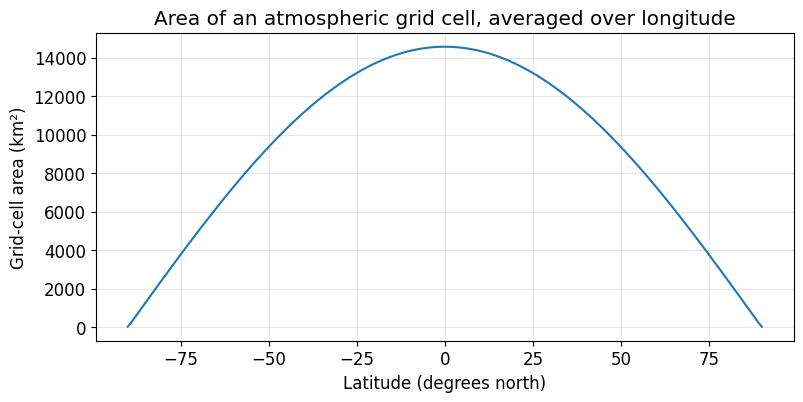

In [15]:
fig, ax = plt.subplots()
(ds.areacella.mean("lon") / 1e6).plot(ax=ax)
ax.set(xlabel="Latitude (degrees north)", ylabel="Grid-cell area (km²)",
       title="Area of an atmospheric grid cell, averaged over longitude")
ax.grid(alpha=0.3)
plt.show()

**Discuss:** Our latitude EBM represented a whole latitude band with one temperature. What additional structure can this model represent? How does the model account for processes that occur at scales smaller than a grid cell?

**Your response:**

## 3. What climate does it produce?

### The annual temperature map

We calculate the annual mean from the twelve climatological months. Longer months receive more weight. This CESM2 simulation uses a **365-day calendar with no leap years**.

**Guess before running:** Besides latitude, what features might explain warm and cold regions on this map?

**Your response:**

In [16]:
temperature_c = ds.tas_clim - 273.15
temperature_c.attrs = {"long_name": "Near-surface air temperature", "units": "°C"}

In [17]:
annual_temperature = temperature_c.weighted(ds.month_days).mean("month")

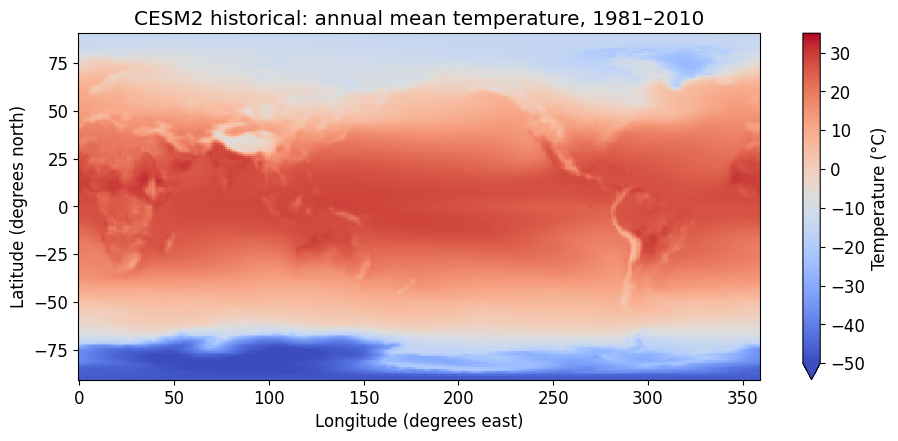

In [18]:
fig, ax = plt.subplots(figsize=(11, 4.5))
annual_temperature.plot(ax=ax, x="lon", y="lat", cmap="coolwarm",
                        vmin=-50, vmax=35, cbar_kwargs={"label": "Temperature (°C)"})
ax.set(title="CESM2 historical: annual mean temperature, 1981–2010",
       xlabel="Longitude (degrees east)", ylabel="Latitude (degrees north)")
plt.show()

### January and July

**Guess before running:** Which hemisphere should be warmer in January? Where might the seasonal contrast be largest, and why?

**Your response:**

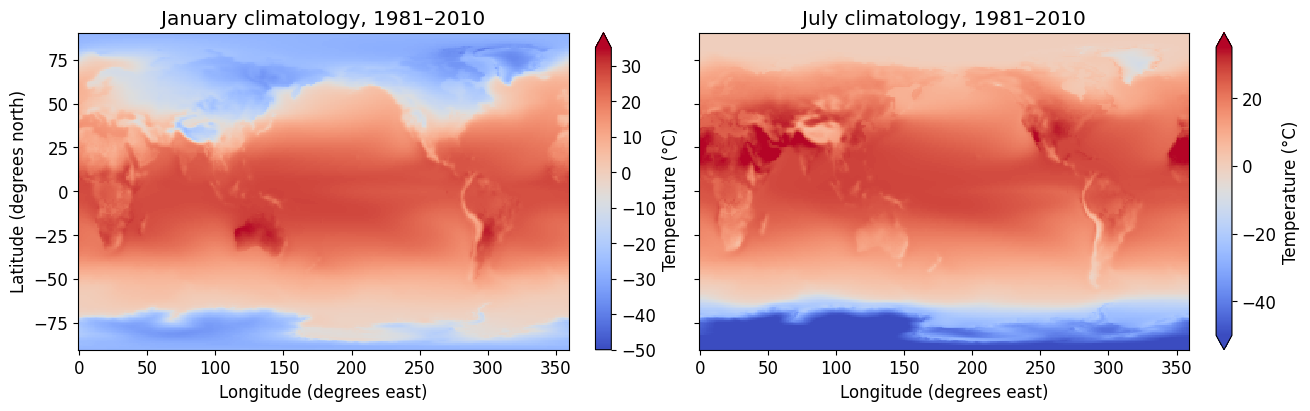

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True, constrained_layout=True)
for ax, month, name in zip(axes, [1, 7], ["January", "July"]):
    temperature_c.sel(month=month).plot(
        ax=ax, x="lon", y="lat", cmap="coolwarm", vmin=-50, vmax=35,
        cbar_kwargs={"label": "Temperature (°C)"})
    ax.set(title=f"{name} climatology, 1981–2010", xlabel="Longitude (degrees east)")
axes[0].set_ylabel("Latitude (degrees north)")
axes[1].set_ylabel("")
plt.show()

**Try it:** Change the two selected months and rerun the cell. Keep the same colour limits so the maps remain comparable.

**Discuss:** Which patterns suggest the role of land and ocean heat storage? What additional data would help test that explanation?

**Your response:**

### A monthly time series at one grid cell

Select the model grid cell nearest New York City. Its temperature represents an area of the model grid. We can compare its monthly temperatures with the average seasonal cycle.

**Guess before running:** Will the average seasonal cycle account for all the changes in temperature? What might remain after we subtract it?

**Your response:**

In [20]:
local_temperature = ds.tas.sel(lat=40.8, lon=286.0, method="nearest") - 273.15
local_climatology = monthly_climatology(local_temperature)
local_anomaly = local_temperature.groupby("time.month") - local_climatology

# Repeat the twelve climatological values over the full time series.
seasonal_cycle = local_climatology.sel(month=local_temperature.time.dt.month)

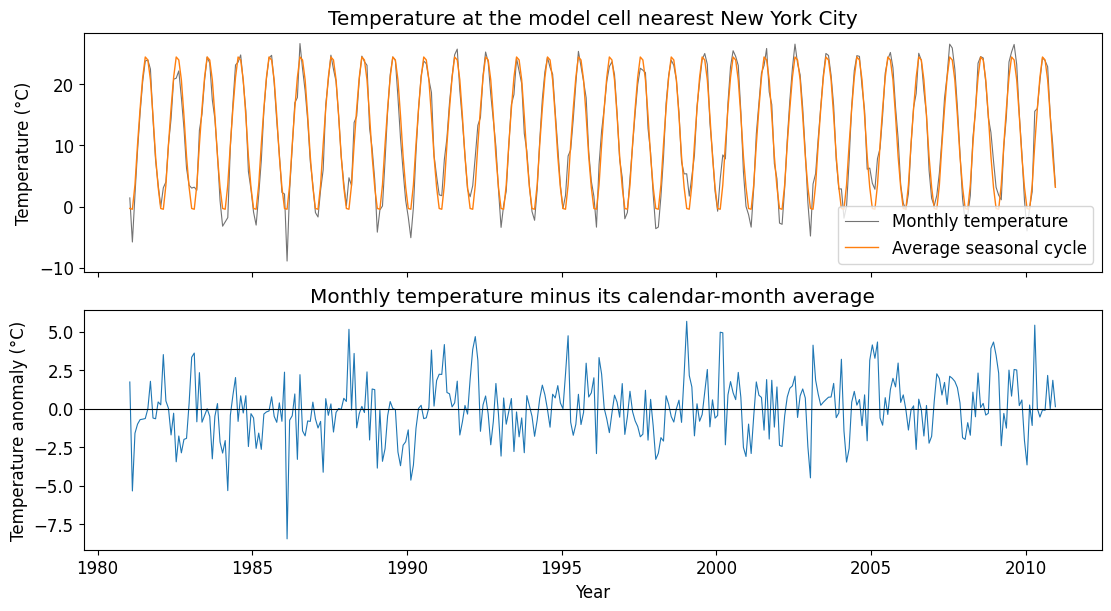

In [21]:
plot_year = local_temperature.time.dt.year + (local_temperature.time.dt.month - 0.5) / 12
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, constrained_layout=True)
axes[0].plot(plot_year, local_temperature, color="0.45", linewidth=0.8, label="Monthly temperature")
axes[0].plot(plot_year, seasonal_cycle, color="tab:orange", linewidth=1, label="Average seasonal cycle")
axes[0].set(title="Temperature at the model cell nearest New York City", ylabel="Temperature (°C)")
axes[0].legend()
axes[1].plot(plot_year, local_anomaly, color="tab:blue", linewidth=0.8)
axes[1].axhline(0, color="k", linewidth=0.8)
axes[1].set(title="Monthly temperature minus its calendar-month average",
            ylabel="Temperature anomaly (°C)", xlabel="Year")
plt.show()

**Discuss:** What did subtracting the seasonal cycle remove? What changes remain? Remember that these are monthly means; individual weather events within a month have already been averaged.

**Your response:**

### Zonal-mean temperature

A **zonal mean** averages around a latitude band. The result is a temperature-versus-latitude curve that we can compare with our latitude EBM. We use cell areas as weights, including within each band.

In [22]:
zonal_temperature = annual_temperature.weighted(ds.areacella).mean("lon")

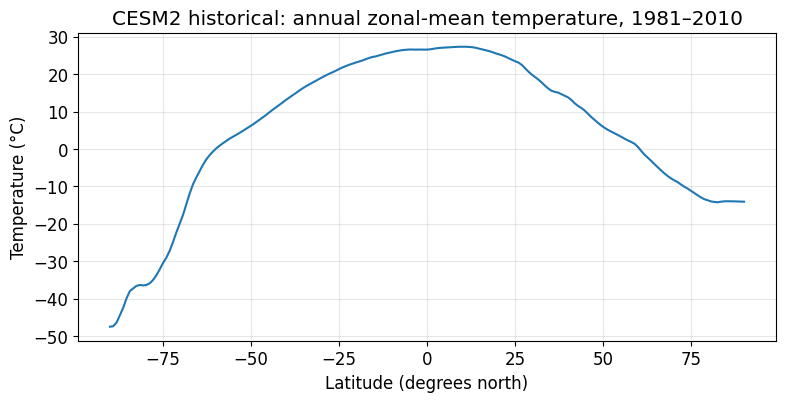

In [23]:
fig, ax = plt.subplots()
zonal_temperature.plot(ax=ax)
ax.set(title="CESM2 historical: annual zonal-mean temperature, 1981–2010",
       xlabel="Latitude (degrees north)", ylabel="Temperature (°C)")
ax.grid(alpha=0.3)
plt.show()

**Discuss:** What information disappeared when we took the zonal mean? Which features could our latitude EBM explain, and which would require more detail?

**Your response:**

## 4. What do we mean by a global average?

A spatial mean should give each square metre equal weight. Averaging grid points equally gives small polar cells as much weight as larger low-latitude cells.

$$\langle T\rangle=\frac{\sum_{i,j} A_{i,j}T_{i,j}}{\sum_{i,j}A_{i,j}}.$$

**Guess before running:** Will the unweighted mean temperature be warmer or colder than the area-weighted mean? Explain your guess.

**Your response:**

In [24]:
unweighted = annual_temperature.mean(("lat", "lon"))
area_weighted = annual_temperature.weighted(ds.areacella).mean(("lat", "lon"))

In [25]:
pd.Series({"Equal weight per grid point (°C)": float(unweighted),
           "Equal weight per unit area (°C)": float(area_weighted),
           "Difference: unweighted − weighted (°C)": float(unweighted - area_weighted)})

Equal weight per grid point (°C)           5.343133
Equal weight per unit area (°C)           14.635761
Difference: unweighted − weighted (°C)    -9.292627
dtype: float64

### Does the global average have a seasonal cycle?

**Guess before running:** Should the two hemispheres’ seasons cancel exactly in the global average? Why might they not?

**Your response:**

In [26]:
global_cycle = temperature_c.weighted(ds.areacella).mean(("lat", "lon"))

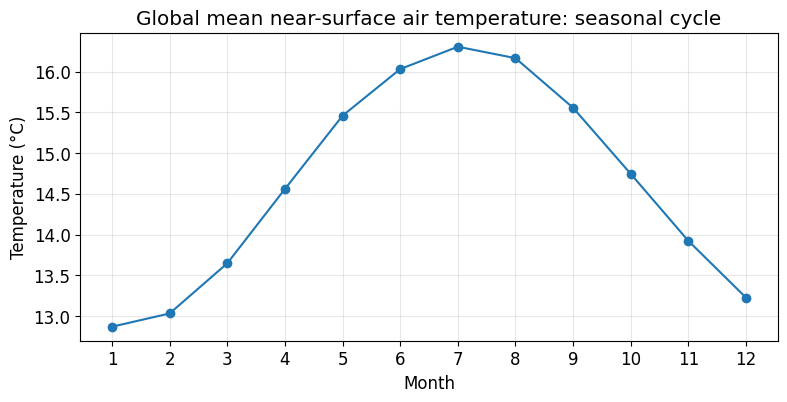

In [27]:
fig, ax = plt.subplots()
global_cycle.plot(ax=ax, marker="o")
ax.set(title="Global mean near-surface air temperature: seasonal cycle",
       xlabel="Month", ylabel="Temperature (°C)", xticks=np.arange(1, 13))
ax.grid(alpha=0.3)
plt.show()

### From monthly output to annual means

The file also contains monthly global means calculated from the original maps. These let us look at changes over the 30 years.

**Guess before running:** In a historical simulation, should each year have the same global temperature? Which kinds of change could appear?

**Your response:**

Weight each month by its number of days. We will use this function for both temperature and radiation.

In [28]:
days = ds.time.dt.days_in_month

def annual_mean(series):
    weighted_sum = (series * days).groupby("time.year").sum("time")
    days_per_year = days.groupby("time.year").sum("time")
    return weighted_sum / days_per_year

In [29]:
annual_global_temperature = annual_mean(ds.tas_global) - 273.15

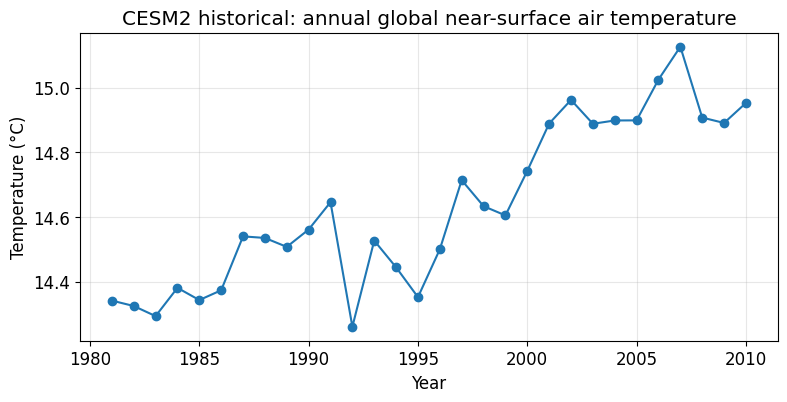

In [30]:
fig, ax = plt.subplots()
annual_global_temperature.plot(ax=ax, marker="o")
ax.set(title="CESM2 historical: annual global near-surface air temperature",
       xlabel="Year", ylabel="Temperature (°C)")
ax.grid(alpha=0.3)
plt.show()

**Discuss:** This curve includes the response to changing external forcings and internal variability. Can one realization separate their contributions? What would additional ensemble members help us establish?

**Your response:**

## 5. What is the planetary energy budget?

At the top of the atmosphere:

$$\mathrm{ASR}=\mathrm{rsdt}-\mathrm{rsut},\qquad
\mathrm{OLR}=\mathrm{rlut},\qquad
N=\mathrm{rsdt}-\mathrm{rsut}-\mathrm{rlut}.$$

**Positive $N$ means net energy entering the climate system.** It can increase heat storage, mainly in the ocean. Top-of-atmosphere radiation alone does not tell us how that heat is distributed.

**Guess before running:** Should incoming sunlight be about 1361 W m⁻² or about a quarter of that in the global average? Should local annual-mean $N$ be zero everywhere?

**Your response:**

In [31]:
radiation_climatology = ds[["rsdt_clim", "rsut_clim", "rlut_clim"]]
annual_radiation = radiation_climatology.weighted(ds.month_days).mean("month")
annual_net = annual_radiation.rsdt_clim - annual_radiation.rsut_clim - annual_radiation.rlut_clim

In [32]:
global_radiation = annual_radiation.weighted(ds.areacella).mean(("lat", "lon"))

global_asr = global_radiation.rsdt_clim - global_radiation.rsut_clim
global_olr = global_radiation.rlut_clim
global_net = global_asr - global_olr
planetary_albedo = global_radiation.rsut_clim / global_radiation.rsdt_clim

In [33]:
budget = pd.Series({
    "Incoming sunlight (W m⁻²)": float(global_radiation.rsdt_clim),
    "Reflected sunlight (W m⁻²)": float(global_radiation.rsut_clim),
    "Absorbed sunlight (W m⁻²)": float(global_asr),
    "Outgoing longwave (W m⁻²)": float(global_olr),
    "Net incoming N (W m⁻²)": float(global_net),
    "Planetary albedo (dimensionless)": float(planetary_albedo),
})
budget.round(3)

Incoming sunlight (W m⁻²)           340.296
Reflected sunlight (W m⁻²)           99.887
Absorbed sunlight (W m⁻²)           240.409
Outgoing longwave (W m⁻²)           239.481
Net incoming N (W m⁻²)                0.928
Planetary albedo (dimensionless)      0.294
dtype: float64

Planetary albedo is the **ratio of global reflected to global incoming sunlight**, rather than the unweighted average of local ratios.

### Where does the planet gain and lose energy?

**Guess before running:** Which latitudes should gain energy from radiation, and which should lose it? How did we represent the connection between those regions in the latitude EBM?

**Your response:**

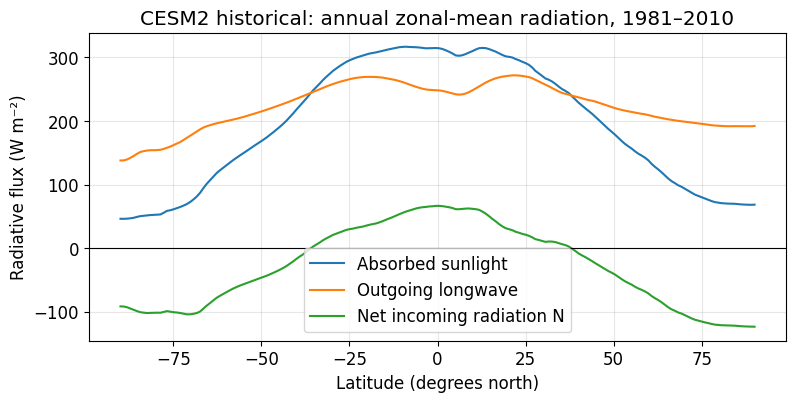

In [34]:
fig, ax = plt.subplots()
for field, label in [(annual_radiation.rsdt_clim - annual_radiation.rsut_clim, "Absorbed sunlight"),
                     (annual_radiation.rlut_clim, "Outgoing longwave"),
                     (annual_net, "Net incoming radiation N")]:
    field.weighted(ds.areacella).mean("lon").plot(ax=ax, label=label)
ax.axhline(0, color="k", linewidth=0.8)
ax.set(title="CESM2 historical: annual zonal-mean radiation, 1981–2010",
       xlabel="Latitude (degrees north)", ylabel="Radiative flux (W m⁻²)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**Discuss:** A local radiative surplus can be balanced by horizontal energy transport and changes in storage. A radiative deficit does not mean a latitude band must keep cooling. What variables would we need to diagnose atmospheric and oceanic transport separately?

**Your response:**

### Does the simulation gain heat over this period?

Historical forcing changes with time. The model need not be in equilibrium, so its global mean $N$ need not be zero. A nonzero value may also include a background model imbalance; comparison with a suitable control run helps diagnose that contribution.

In [35]:
monthly_net_global = ds.rsdt_global - ds.rsut_global - ds.rlut_global
annual_net_global = annual_mean(monthly_net_global)

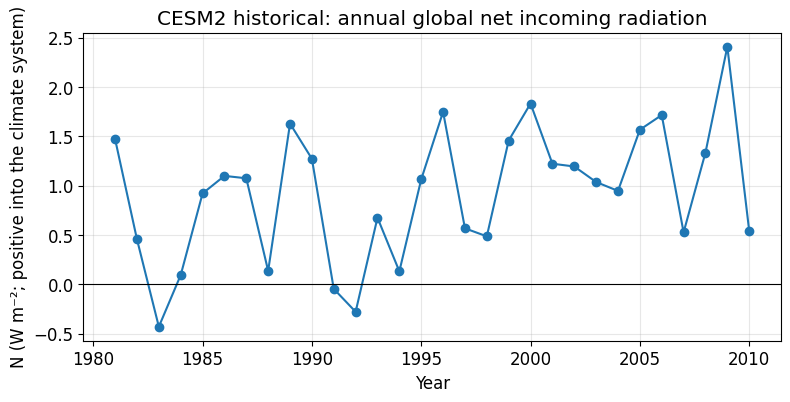

1981–2010 mean N: 0.928 W m⁻²


In [36]:
fig, ax = plt.subplots()
annual_net_global.plot(ax=ax, marker="o")
ax.axhline(0, color="k", linewidth=0.8)
ax.set(title="CESM2 historical: annual global net incoming radiation",
       xlabel="Year", ylabel="N (W m⁻²; positive into the climate system)")
ax.grid(alpha=0.3)
plt.show()
print(f"1981–2010 mean N: {float(monthly_net_global.weighted(days).mean('time')):.3f} W m⁻²")

## 6. What have we learned about this simulated climate?

Choose one of the plots and answer:

1. What physical feature of the simulated climate does it reveal?
2. What averaging or weighting did we use, and what information did it remove?
3. What observation or additional model variable would you use to evaluate your interpretation?

**Your response:**

To evaluate the model, we would need observations of the same quantities, averaged over comparable areas and periods. To estimate forcing or feedbacks, we would also need an appropriate experiment and reference climate.

## Optional: choose another question

- **Seasonal contrast:** Map July minus January temperature. Where is the contrast strongest?
- **Hemispheric contrast:** Calculate the annual mean temperature of each hemisphere using cell-area weights. Explain your result.
- **Radiation map:** Map annual $N$. What spatial structure disappeared in the zonal mean?

Write down your question and **guess** before adding a calculation.

### Credits and references

Teaching sequence inspired by Brian E. J. Rose, [*The Climate Laboratory: Introducing CESM*](https://brian-rose.github.io/ClimateLaboratoryBook/courseware/introducing-cesm/) (CC BY 4.0). The data used here are CMIP6 output from CESM2.

We acknowledge NCAR and the CESM contributors, the WCRP CMIP community, the Earth System Grid Federation, and Pangeo for producing and providing access to these data. Original dataset metadata are available from the cloud stores listed in the preparation cells. Model description: [Danabasoglu et al. (2020), *The Community Earth System Model Version 2 (CESM2)*](https://doi.org/10.1029/2019MS001916).

Prepared for Introduction to Climate Modeling, Columbia Climate School, Fall 2026.